# Token-economy lab — modeling, simulating and validating (Lectures 4.5–4.6)

One cadCAD model of a community token economy, applied to the three cases specified in
Domenicale, Avanzo & Schifanella (2026): NLAB4CIT, CORPUS and FoodReborn.

1. The model: supply as a stock, emission and burn as flows.
2. The three cases and their parameters.
3. Baseline simulation (two simulated years).
4. Validating the six sustainability conditions on the simulation — with the scope of each check stated.
5. Stress tests I: parameter sweeps (cadCAD `M` lists).
6. Stress tests II: Monte Carlo demand shocks (cadCAD `N` runs).
7. Formal verification of the threshold conditions with Z3 (SMT).
8. The pre-deployment risk profile.
9. Reference solutions to the exercise.

**What this laboratory checks.** Of the six sustainability conditions of Lecture 4.4, this
laboratory validates **FM1 (oversupply)** and **FM3 (burn coverage)** *dynamically*, on the
simulated trajectories; **FM2 (velocity trap)** only in its supply-side manifestation, since
`V > V* = PQ/M` is equivalent to `M > M*`, while its behavioural side (the holding time
`τ̄`) is checked *statically* on the design parameters; and **FM4 (contribution),
FM5 (critical mass) and FM6 (governance)** *statically*, because a stock-flow model
contains no individual agents and no governance process.

In [1]:
import io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cadCAD.configuration import Experiment
from cadCAD.configuration.utils import config_sim
from cadCAD.engine import ExecutionContext, Executor, ExecutionMode

# -- simulation setup (single source of truth for every experiment below) --
T_WEEKS        = 104     # horizon: two years, weekly steps
INITIAL_SUPPLY = 1000.0  # tokens in circulation at week zero
SEED           = 42      # base seed: makes every stochastic result reproducible

# -- stress-test setup --
SIGMA_Q_MC     = 0.25    # assumed relative std. dev. of weekly volume (Monte Carlo)
N_RUNS_MC      = 50      # Monte Carlo repetitions
DIP_FRACTION   = 0.5     # a run "dips" if supply ever falls below this share of start

# -- reporting --
FIG_DIR  = "figs"        # figures are saved here for the slides
import os as _os; _os.makedirs(FIG_DIR, exist_ok=True)  # ensure figs/ exists on a clean run
FIG_DPI  = 200
FIGSIZE  = (7.6, 3.8)

def save_show(name):
    """Finish the current figure: tight layout, save for the slides, display."""
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=FIG_DPI); plt.show()

pd.set_option("display.precision", 2)
from importlib.metadata import version as pkg_version
print(f"cadCAD {pkg_version('cadCAD')} · z3-solver {pkg_version('z3-solver')}")

cadCAD 0.5.3 · z3-solver 4.16.0.0


## 1. The model

The model is a **discrete-time stock-flow model**: a *stock* is a quantity that persists
from period to period (here the token supply), a *flow* is a change per period (here the
emission and the burn), and time advances in weekly steps. With fixed parameters the model
is **deterministic** — the same inputs always produce the same trajectory.

The state is the token supply `M(t)`. One policy computes the week's flows — the realized
transaction volume `q` (equal to the parameter `Q`, or drawn around it when `sigma_Q > 0`),
the emission `E`, and the burn (a fraction of `q` when the design has a demand-driven burn).
The state updates apply `M(t+1) = M(t) + emission − burn` and record the consistent supply
`M* = P·Q/V` (price normalised to one), the oversupply ratio `M(t)/M*` and the week's burn
coverage `ρ = burn/emission`.

In [2]:
# --- policy: computes the week's flows from the parameters and the previous state ---
# cadCAD signature: (params, substep, state_history, previous_state) -> dict of signals.
# A policy READS the state and never writes it.
def p_flows(params, substep, history, prev):
    """Weekly flows. The realized volume q equals Q, or is drawn around Q in Monte
    Carlo runs; the burn cannot destroy more tokens than exist this week."""
    if params["sigma_Q"] > 0:
        # seeded per (run, week): distinct draws per run, reproducible in any execution mode
        rng = np.random.default_rng([SEED, prev["run"], prev["timestep"]])
        q = params["Q"] * max(0.0, 1.0 + params["sigma_Q"] * rng.standard_normal())
    else:
        q = params["Q"]
    burn = params["burn_frac"] * q if params["burn_mode"] == "demand" else 0.0
    return {"emission": params["E"], "burn": min(burn, prev["supply"] + params["E"])}

# --- state updates: apply the flows to the stock and record them ---
# cadCAD signature: (params, substep, state_history, previous_state, policy_input)
# -> a pair (state variable, new value).
def s_supply(params, substep, history, prev, policy):
    return ("supply", prev["supply"] + policy["emission"] - policy["burn"])

def s_emission(params, substep, history, prev, policy):
    return ("emission_t", policy["emission"])     # recorded so metrics can be derived

def s_burn(params, substep, history, prev, policy):
    return ("burn_t", policy["burn"])

# --- partial state update blocks: each block is one SUBSTEP; the whole list
#     runs once per timestep. One block here, so one substep per week. ---
PSUBS = [{"policies":  {"flows": p_flows},
          "variables": {"supply": s_supply, "emission_t": s_emission, "burn_t": s_burn}}]

INITIAL_STATE = {"supply": INITIAL_SUPPLY, "emission_t": 0.0, "burn_t": 0.0}

The model holds only true state — the supply — plus the recorded weekly flows.
Everything derived (the consistent supply `M*`, the oversupply ratio, the burn coverage
`ρ`) is computed *from* the simulation output by a separate function, so the model and
the reporting stay decoupled.

## 2. The three cases

Every parameter below is marked as **(paper)** — reported in Domenicale et al. (2026),
Tables 2–3; **(derived)** — computed from paper values by a stated formula; or
**(assumed)** — a course-set value, with its rationale. Where the paper reports a
diagnostic ratio, the derived parameters reproduce it, so the simulation stays as close
as possible to the reference cases.

In [3]:
# --- NLAB4CIT: volunteer rewards -------------------------------------------------
NLAB_E       = 750.0            # tokens minted per week                     (paper)
NLAB_N       = 100              # participants                               (paper)
NLAB_K       = 8                # offer types: the eight merchants           (paper)
NLAB_D       = 2.0              # coupon demand per participant per week     (assumed)
NLAB_Q       = NLAB_D * NLAB_N  # volume 200/week (derived from ASSUMED d: Q = d·N)
NLAB_TAU     = 1.5              # wealth-weighted holding time, in weeks     (paper, Table 3)
NLAB_V       = 1.0 / NLAB_TAU   # velocity, the paper's V = 1/tau bound      (derived)
NLAB_GAMMA   = 1.0              # governance centralisation                  (paper, Table 3)
NLAB_PHI     = 0.45             # contributor share                          (assumed)

# --- CORPUS: the Library of Things ------------------------------------------------
CORPUS_V     = 0.14             # velocity per week: the escrow effect       (paper, §4.4)
CORPUS_TAU   = 7.0              # paper says "~7 days"; used as 7 weekly periods, the only
                                #   reading consistent with the paper's own V = 0.14/week = 1/7
CORPUS_E     = 60.0             # weekly reward emission                     (assumed: reward schedule scale)
CORPUS_RATIO = 0.105            # target E/M* reported by the paper (~0.10)  (paper, Table 3)
CORPUS_Q     = CORPUS_E / CORPUS_RATIO * CORPUS_V   # -> 80/week             (derived: reproduces E/M*)
CORPUS_N     = 40               # participants                               (assumed: community scale)
CORPUS_K     = 60               # offer types: distinct objects              (assumed: item-specific matching)
CORPUS_D     = 1.0              # borrowing demand per participant per week  (assumed)
CORPUS_GAMMA = 0.8              # governance centralisation                  (paper, Table 3)
CORPUS_PHI   = 0.50             # contributor (lender) share                 (assumed)

# --- FoodReborn: food redistribution ----------------------------------------------
FOOD_E       = 400.0            # tokens/week: two collections of 100 kg at ~2 EUR/kg (assumed scale,
                                #   anchored to the paper's example 100 kg x 2.00 = 200 tokens)
FOOD_Q       = 400.0            # redemption ~ emission (derived from ASSUMED E: flow design)
FOOD_TAU     = 2.0              # holding time, high redemption pressure             (assumed)
FOOD_V       = 1.2              # velocity; respects the bound V >= 1/tau = 0.5      (assumed)
FOOD_N       = 30               # beneficiaries                                      (assumed)
FOOD_K       = 5                # offer types: participating restaurants             (assumed)
FOOD_D       = 1.5              # meal demand per beneficiary per week               (assumed)
FOOD_GAMMA   = 1.0              # governance centralisation                          (paper, Table 3)
FOOD_PHI     = 0.30             # contributing (supplying) share                     (assumed)

SIM = {
    "NLAB4CIT":   dict(E=NLAB_E,   burn_mode="none",   burn_frac=0.0, Q=NLAB_Q,   V=NLAB_V,   sigma_Q=0.0),
    "CORPUS":     dict(E=CORPUS_E, burn_mode="none",   burn_frac=0.0, Q=CORPUS_Q, V=CORPUS_V, sigma_Q=0.0),
    "FoodReborn": dict(E=FOOD_E,   burn_mode="demand", burn_frac=1.0, Q=FOOD_Q,   V=FOOD_V,   sigma_Q=0.0),
}
STATIC = {
    "NLAB4CIT":   dict(phi=NLAB_PHI,   d=NLAB_D,   K=NLAB_K,   N=NLAB_N,   Gamma=NLAB_GAMMA,   tau_bar=NLAB_TAU,   holding_incentive=False),
    "CORPUS":     dict(phi=CORPUS_PHI, d=CORPUS_D, K=CORPUS_K, N=CORPUS_N, Gamma=CORPUS_GAMMA, tau_bar=CORPUS_TAU, holding_incentive=True),
    "FoodReborn": dict(phi=FOOD_PHI,   d=FOOD_D,   K=FOOD_K,   N=FOOD_N,   Gamma=FOOD_GAMMA,   tau_bar=FOOD_TAU,   holding_incentive=False),
}

# cross-check against the paper's reported diagnostics (Table 3)
check = pd.DataFrame({
    name: {"E/M* here": round(p["E"] / (p["Q"] / p["V"]), 2)} for name, p in SIM.items()}).T
check["E/M* in the paper"] = ["~2.5", "~0.10", "not reported"]
check

,E/M* here,E/M* in the paper
NLAB4CIT,2.5,~2.5
CORPUS,0.1,~0.10
FoodReborn,1.2,not reported


## 3. Baseline simulation

`simulate` wraps the cadCAD constructs: `config_sim` (horizon `T`, runs `N`, parameters `M`),
`Experiment.append_model`, and the local-mode `Executor`. A sweep passes several values for
one parameter: cadCAD pairs equal-length `M` lists element-wise, one *subset* per element.

In [4]:
def _metrics(df, params, sweep=None):
    """Derive the reported quantities from the raw output (pure function, no state).
    When Q or V is the swept parameter, each subset uses its own swept value."""
    q, v = params["Q"], params["V"]
    if sweep is not None and sweep[0] in ("Q", "V"):
        swept = df.subset.map(dict(enumerate(sweep[1])))
        q = swept if sweep[0] == "Q" else q
        v = swept if sweep[0] == "V" else v
    m_star = q / v                                       # M* = P·Q/V with P = 1
    return df.assign(m_star=m_star,
                     oversupply_ratio=df.supply / m_star,
                     rho=np.where(df.emission_t > 0, df.burn_t / df.emission_t, np.nan))

def simulate(params, T=T_WEEKS, n_runs=1, sweep=None):
    """Run the model with cadCAD and return one tidy row per (subset, run, week).

    cadCAD constructs used, in order:
      config_sim  -- T: the horizon; N: the number of runs (N > 1 = Monte Carlo);
                     M: the parameters, each a LIST; equal-length lists are paired
                     element-wise, one *subset* per element (a parameter sweep).
      Experiment  -- registers initial state, update blocks and configuration.
      Executor    -- executes in local mode; returns one record per substep.
    """
    if sweep is None:
        m = {k: [v] for k, v in params.items()}
    else:
        name, values = sweep
        m = {k: [v] * len(values) for k, v in params.items()}
        m[name] = list(values)
    exp = Experiment()
    exp.append_model(initial_state=INITIAL_STATE,
                     partial_state_update_blocks=PSUBS,
                     sim_configs=config_sim({"T": range(T), "N": n_runs, "M": m}))
    executor = Executor(exec_context=ExecutionContext(context=ExecutionMode().local_mode),
                        configs=exp.configs)
    with contextlib.redirect_stdout(io.StringIO()):      # silence the cadCAD banner
        records, _, _ = executor.execute()
    df = (pd.DataFrame(records)
            .groupby(["subset", "run", "timestep"]).last()   # final substate per week
            .reset_index())
    return _metrics(df, params, sweep)

baseline = {name: simulate(p) for name, p in SIM.items()}

summary = pd.DataFrame({name: {
    "final supply":    df.supply.iloc[-1],
    "M* (consistent)": df.m_star.iloc[-1],
    "oversupply x":    round(df.oversupply_ratio.iloc[-1], 1)}
    for name, df in baseline.items()}).T
summary

Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/105 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/105 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/105 [00:00<?, ?it/s]

,final supply,M* (consistent),oversupply x
NLAB4CIT,79000.0,300.00,263.3
CORPUS,7240.0,571.43,12.7
FoodReborn,1000.0,333.33,3.0


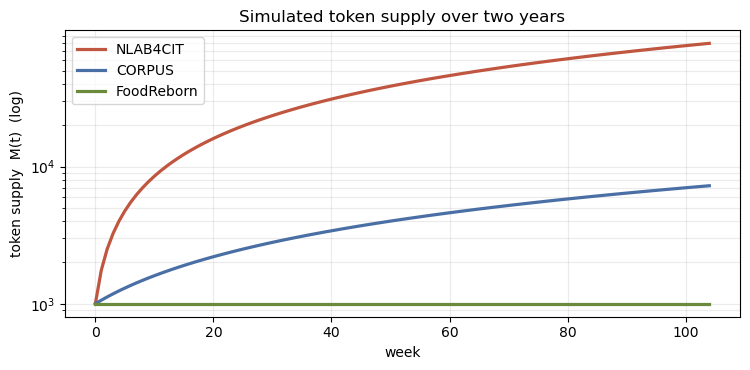

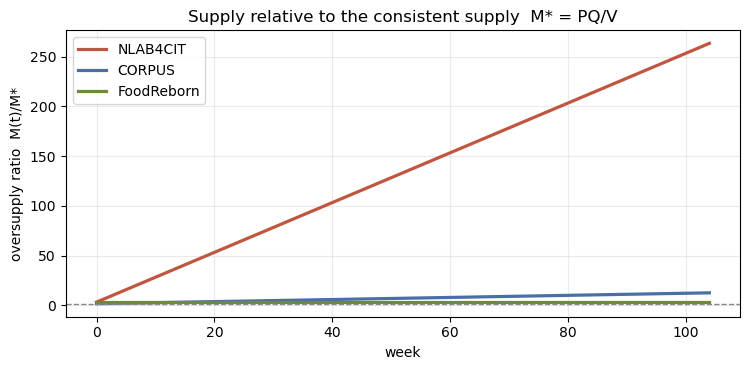

In [5]:
COL = {"NLAB4CIT": "#c05640", "CORPUS": "#4a6fa5", "FoodReborn": "#6c8a3c"}

fig, ax = plt.subplots(figsize=FIGSIZE)
for name, df in baseline.items():
    ax.plot(df.timestep, df.supply, color=COL[name], lw=2.3, label=name)
ax.set_yscale("log"); ax.set_xlabel("week"); ax.set_ylabel("token supply  M(t)  (log)")
ax.set_title("Simulated token supply over two years")
ax.legend(); ax.grid(alpha=0.25, which="both"); save_show("f4546_supply")

fig, ax = plt.subplots(figsize=FIGSIZE)
for name, df in baseline.items():
    ax.plot(df.timestep, df.oversupply_ratio, color=COL[name], lw=2.3, label=name)
ax.axhline(1.0, color="#888", ls="--", lw=1)
ax.set_xlabel("week"); ax.set_ylabel("oversupply ratio  M(t)/M*")
ax.set_title("Supply relative to the consistent supply  M* = PQ/V")
ax.legend(); ax.grid(alpha=0.25); save_show("f4546_ratio")

## 4. Validating the six conditions on the simulation

The model can check each condition only within its scope:

| Condition | How it is checked here | Scope |
|---|---|---|
| FM1 oversupply | the trajectory `M(t)` against `M*` | **dynamic** (simulated) |
| FM3 burn coverage | `ρ = burn/emission` from the simulated flows | **dynamic** (simulated) |
| FM2 velocity trap | `V > V* = PQ/M` is *equivalent* to `M > M*`, so the trap is seen only through supply; the behavioural side (`τ̄ → 1`) is a static check on the design | **partial** |
| FM4 contribution | `φ ≥ d/K` on the design parameters | **static** |
| FM5 critical mass | `N ≥ 2·K·d + 1` on the design parameters | **static** |
| FM6 governance | `Γ ≤ 0.5` on the governance structure | **static** — no governance dynamics in a stock-flow model |

In [6]:
def weeks_until(df, factor=2.0):
    """First week at which supply exceeds `factor` times its starting value (NaN if never)."""
    over = df[df.supply > factor * INITIAL_SUPPLY]
    return int(over.timestep.iloc[0]) if len(over) else np.nan

def validate(name):
    df, s, p = baseline[name], STATIC[name], SIM[name]
    m_star = p["Q"] / p["V"]
    return {
        "FM1 E/M* (design)":     round(p["E"] / m_star, 3),
        "FM1 final M/M*":        round(df.oversupply_ratio.iloc[-1], 1),
        "FM1 weeks to 2x":       weeks_until(df),
        "FM3 rho (mean)":        round(df.rho.dropna().mean(), 2),
        "FM2 tau_bar":           s["tau_bar"],
        "FM2 holding incentive": s["holding_incentive"],
        "FM4 phi >= d/K":        s["phi"] >= s["d"] / s["K"],
        "FM5 N >= 2Kd+1":        s["N"] >= 2 * s["K"] * s["d"] + 1,
        "FM6 Gamma <= 0.5":      s["Gamma"] <= 0.5,
    }

validation = pd.DataFrame({name: validate(name) for name in SIM}).T
validation

,FM1 E/M* (design),FM1 final M/M*,FM1 weeks to 2x,FM3 rho (mean),FM2 tau_bar,FM2 holding incentive,FM4 phi >= d/K,FM5 N >= 2Kd+1,FM6 Gamma <= 0.5
NLAB4CIT,2.5,263.3,2,0.0,1.5,False,True,True,False
CORPUS,0.1,12.7,17,0.0,7.0,True,True,False,False
FoodReborn,1.2,3.0,NaN,1.0,2.0,False,True,True,False


## 5. Stress tests I — parameter sweeps

A **parameter sweep** repeats the simulation for several values of one parameter,
holding all the others fixed, to show how the outcome depends on that parameter.
It answers: across which range of the parameter does a condition hold?
Here: which demand-driven burn fraction would bound NLAB4CIT's supply, and which
emission would, at a full transaction burn.

The sweeps expose three regimes, not two: below the balance point the supply grows
without bound; at the balance point (burn = emission, i.e. `burn_frac = E/Q`) it is
constant; above it the burn drains the supply to zero — a bounded economy, but one
with no tokens left to circulate, which is a different failure, not a success.

In [7]:
nlab = SIM["NLAB4CIT"] | {"burn_mode": "demand"}
BALANCE_FRAC = nlab["E"] / nlab["Q"]     # burn = emission requires burn_frac = E/Q
BALANCE_E    = nlab["Q"]                 # at a full transaction burn, balance needs E = Q

fracs = np.round(np.arange(0.0, BALANCE_FRAC + 0.76, 0.75), 2)
sw_frac = simulate(nlab, sweep=("burn_frac", list(fracs)))
final_by_frac = sw_frac.groupby("subset").last().assign(burn_frac=fracs)[
    ["burn_frac", "supply", "oversupply_ratio"]]

emissions = np.round(np.arange(100.0, 801.0, 100.0), 0)
sw_e = simulate(nlab | {"burn_frac": 1.0}, sweep=("E", list(emissions)))
final_by_E = sw_e.groupby("subset").last().assign(E=emissions)[["E", "supply", "oversupply_ratio"]]

print(f"balance requires burn_frac = E/Q = {BALANCE_FRAC:.2f}: every transaction would have")
print(f"to burn {BALANCE_FRAC:.2f}x its own volume; at a full burn, emission must fall to Q = {BALANCE_E:.0f}.")
final_by_frac

Initializing configurations:   0%|          | 0/7 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/7 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/8 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/8 [00:00<?, ?it/s]

balance requires burn_frac = E/Q = 3.75: every transaction would have
to burn 3.75x its own volume; at a full burn, emission must fall to Q = 200.


,burn_frac,supply,oversupply_ratio
subset,,,
0,0.00,79000.0,263.33
1,0.75,63400.0,211.33
2,1.50,47800.0,159.33
3,2.25,32200.0,107.33
4,3.00,16600.0,55.33
5,3.75,1000.0,3.33
6,4.50,0.0,0.00


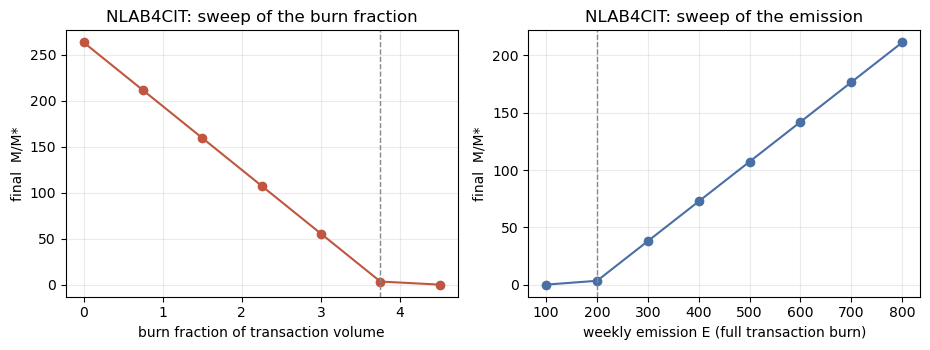

,E,supply,oversupply_ratio
subset,,,
0,100.0,0.0,0.00
1,200.0,1000.0,3.33
2,300.0,11400.0,38.00
3,400.0,21800.0,72.67
4,500.0,32200.0,107.33
5,600.0,42600.0,142.00
6,700.0,53000.0,176.67
7,800.0,63400.0,211.33


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.6))
ax[0].plot(final_by_frac.burn_frac, final_by_frac.oversupply_ratio, "o-", color="#c05640")
ax[0].axvline(BALANCE_FRAC, color="#888", ls="--", lw=1)
ax[0].set_xlabel("burn fraction of transaction volume"); ax[0].set_ylabel("final  M/M*")
ax[0].set_title("NLAB4CIT: sweep of the burn fraction")
ax[1].plot(final_by_E.E, final_by_E.oversupply_ratio, "o-", color="#4a6fa5")
ax[1].axvline(BALANCE_E, color="#888", ls="--", lw=1)
ax[1].set_xlabel("weekly emission E (full transaction burn)"); ax[1].set_ylabel("final  M/M*")
ax[1].set_title("NLAB4CIT: sweep of the emission")
for a in ax: a.grid(alpha=0.25)
save_show("f4546_sweeps")
final_by_E

## 6. Stress tests II — Monte Carlo demand shocks

A **Monte Carlo simulation** repeats the same experiment many times with random draws for
the quantities that are uncertain, so that the collection of outcomes approximates the
*distribution* of possible results, rather than one trajectory. Each repetition is a *run*;
in cadCAD, `N` sets the number of runs. Here the uncertain quantity is the weekly
transaction volume, drawn around `Q` with relative standard deviation `sigma_Q` (an assumed
uncertainty level, set to 0.25).

Randomness is kept **reproducible** by seeding: a *seed* fixes the state of the random
number generator, so the same draws recur on every re-execution. Because cadCAD may execute
runs in parallel processes, the generator is seeded per run and week, with
`(SEED, run, timestep)`, which makes every run distinct and the whole experiment
reproducible in any execution mode.

The question: does FoodReborn's bounded supply survive demand uncertainty?

Initializing configurations:   0%|          | 0/50 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/50 [00:00<?, ?it/s]

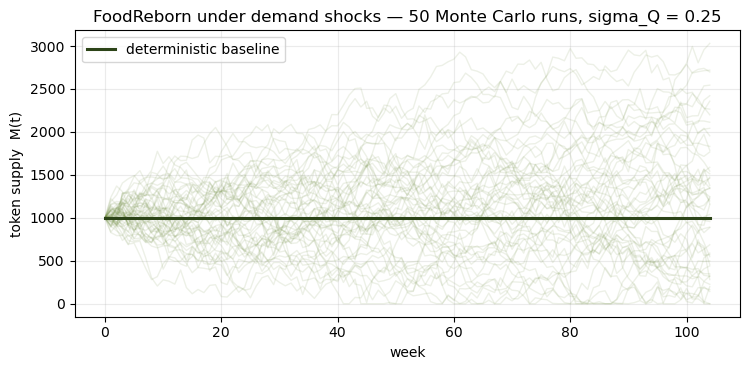

final M/M* across runs:  mean 3.69   5-95% [0.46, 7.89]
runs whose supply ever falls below 50% of its starting value: 24 of 50


In [9]:
mc = simulate(SIM["FoodReborn"] | {"sigma_Q": SIGMA_Q_MC}, n_runs=N_RUNS_MC)

fig, ax = plt.subplots(figsize=FIGSIZE)
for r, df in mc.groupby("run"):
    ax.plot(df.timestep, df.supply, color="#6c8a3c", alpha=0.12, lw=1)
ax.plot(baseline["FoodReborn"].timestep, baseline["FoodReborn"].supply,
        color="#2c4418", lw=2.2, label="deterministic baseline")
ax.set_xlabel("week"); ax.set_ylabel("token supply  M(t)")
ax.set_title(f"FoodReborn under demand shocks — {N_RUNS_MC} Monte Carlo runs, sigma_Q = {SIGMA_Q_MC}")
ax.legend(); ax.grid(alpha=0.25); save_show("f4546_montecarlo")

finals = mc.groupby("run").last().oversupply_ratio
dip = mc.groupby("run").supply.min() < DIP_FRACTION * INITIAL_SUPPLY
print(f"final M/M* across runs:  mean {finals.mean():.2f}   5-95% [{finals.quantile(0.05):.2f}, {finals.quantile(0.95):.2f}]")
print(f"runs whose supply ever falls below {DIP_FRACTION:.0%} of its starting value: {int(dip.sum())} of {len(dip)}")

## 7. Formal verification of the threshold conditions with Z3

The static conditions were checked above at single point values. The paper's
parameter-box idea asks more: does a condition hold across the whole **range** each
uncertain parameter may take? For threshold conditions this is a question of
**satisfiability**, and it is answered exactly — with proofs, not samples — by an
**SMT solver** (satisfiability modulo theories): a program that decides whether a set of
logical constraints over arithmetic has a solution (*sat*, with a **model**, a concrete
satisfying assignment) or provably has none (*unsat*). We use **Z3**, an open-source SMT
solver by Microsoft Research (`pip install z3-solver`).

The verdicts become two satisfiability queries per condition over the declared box:

* **sound** — the *negation* of the condition is unsat over the box (no assignment violates it);
* **broken** — the condition itself is unsat over the box (no assignment satisfies it);
* **fragile** — both are sat; Z3 then exhibits a **counterexample**, a parameter
  assignment inside the box that violates the condition.

The boxes below are course-set ranges centred on the case values, declared once with
their provenance.

In [10]:
from z3 import (Real, Int, Reals, Ints, Bool, Solver, Not, And, Implies,
                ForAll, sat, unsat)

# Declared parameter boxes (course-set ranges around the case values of Section 2)
BOXES = {
    "NLAB4CIT":   dict(phi=(0.30, 0.60), d=(1.0, 3.0), K=(6, 10),  N=(80, 120),
                       Gamma=(0.9, 1.0), Q=(150.0, 250.0), V=(0.5, 0.8)),
    "CORPUS":     dict(phi=(0.35, 0.65), d=(0.5, 1.5), K=(40, 80), N=(30, 60),
                       Gamma=(0.7, 0.9), Q=(60.0, 100.0),  V=(0.10, 0.20)),
    "FoodReborn": dict(phi=(0.25, 0.35), d=(1.0, 2.0), K=(4, 6),   N=(25, 40),
                       Gamma=(0.9, 1.0), Q=(300.0, 500.0), V=(1.0, 1.4)),
}

def _symbols():
    phi, d, Gamma, Q, V = Reals("phi d Gamma Q V")
    K, N = Ints("K N")
    return dict(phi=phi, d=d, K=K, N=N, Gamma=Gamma, Q=Q, V=V)

def _in_box(v, box):
    return [c for name, x in v.items() for c in (x >= box[name][0], x <= box[name][1])]

def _conditions(v, E):
    """The threshold conditions as Z3 constraints (phi >= d/K written product-form)."""
    return {"FM1 design": E * v["V"] <= v["Q"],          # E <= M* = Q/V
            "FM4":        v["phi"] * v["K"] >= v["d"],
            "FM5":        v["N"] >= 2 * v["K"] * v["d"] + 1,
            "FM6":        v["Gamma"] <= 0.5}

def box_verdict(case):
    """sound / fragile (with counterexample) / broken, per condition, over the box."""
    v, box, E = _symbols(), BOXES[case], SIM[case]["E"]
    out = {}
    for name, cond in _conditions(v, E).items():
        can_violate = Solver(); can_violate.add(_in_box(v, box)); can_violate.add(Not(cond))
        can_satisfy = Solver(); can_satisfy.add(_in_box(v, box)); can_satisfy.add(cond)
        if can_violate.check() == unsat:   out[name] = "sound"
        elif can_satisfy.check() == unsat: out[name] = "broken"
        else:
            m = can_violate.model()
            witness = ", ".join(f"{k}={m[x]}" for k, x in v.items() if m[x] is not None)
            out[name] = f"fragile ({witness})"
    return out

z3_verdicts = pd.DataFrame({c: box_verdict(c) for c in BOXES}).T
z3_verdicts

,FM1 design,FM4,FM5,FM6
NLAB4CIT,broken,"fragile (phi=3/10, d=29/10, K=9, N=80, Gamma=9...",sound,broken
CORPUS,sound,sound,"fragile (phi=7/20, d=1/2, K=80, N=46, Gamma=7/...",broken
FoodReborn,"fragile (phi=1/4, d=1, K=4, N=25, Gamma=9/10, ...","fragile (phi=9/32, d=7/4, K=6, N=25, Gamma=9/1...",sound,broken


**Reading the verdicts.** `sound` and `broken` are *proofs*: Z3 shows the query
unsatisfiable over the entire box, something no amount of sampling can establish.
`fragile` comes with a counterexample — the concrete parameter assignment that breaks
the condition. Note how ranges change the picture relative to the point checks:
NLAB4CIT's contribution condition, satisfied at the point values, is fragile across its
box; CORPUS's critical mass, failed at the point values, is fragile — parts of its box
satisfy it.

### Joint feasibility, and the blocking condition

A design is feasible only if *some* assignment in the box satisfies **all** the
conditions at once. When the answer is no, Z3's **unsat core** names a set of
asserted conditions responsible for the conflict (not guaranteed to be the smallest
such set) — automatic root-cause isolation.

In [11]:
def joint_feasibility(case):
    v, box, E = _symbols(), BOXES[case], SIM[case]["E"]
    s = Solver(); s.set(unsat_core=True)
    s.add(_in_box(v, box))
    for name, cond in _conditions(v, E).items():
        s.assert_and_track(cond, Bool(name))            # label each condition
    if s.check() == sat:
        m = s.model()
        return "feasible: " + ", ".join(f"{k}={m[x]}" for k, x in v.items())
    return "infeasible — blocking: " + ", ".join(str(b) for b in s.unsat_core())

for case in BOXES:
    print(f"{case:12s} {joint_feasibility(case)}")

NLAB4CIT     infeasible — blocking: FM1 design
CORPUS       infeasible — blocking: FM6
FoodReborn   infeasible — blocking: FM6


### Minimal repairs

For a monotone threshold condition the binding point of a box is a **corner**: the
critical-mass requirement `N ≥ 2Kd + 1` is hardest at the largest `K` and `d`, and the
contribution requirement `φ ≥ d/K` at the largest `d` and smallest `K`. The smallest
robust repair therefore comes from the binding corner — and Z3 *verifies* the
resulting value with a universally quantified check (`ForAll`) over the whole box.

In [12]:
import math

def minimal_repairs():
    rows = {}
    # CORPUS, FM5: extra participants needed at the binding corner (K_max, d_max)
    b = BOXES["CORPUS"]
    need = 2 * b["K"][1] * b["d"][1] + 1                 # 2·80·1.5 + 1 = 241
    dN = max(0, math.ceil(need - b["N"][0]))
    K, d = Int("K"), Real("d")
    check = Solver()
    check.add(Not(ForAll([K, d], Implies(
        And(K >= b["K"][0], K <= b["K"][1], d >= b["d"][0], d <= b["d"][1]),
        b["N"][0] + dN >= 2 * K * d + 1))))
    rows["CORPUS: extra participants for FM5"] = (dN, "verified" if check.check() == unsat else "NOT verified")
    # FoodReborn, FM4: extra contributor share at the binding corner (d_max, K_min)
    b = BOXES["FoodReborn"]
    dphi = max(0.0, b["d"][1] / b["K"][0] - b["phi"][0]) # 2/4 - 0.25 = 0.25
    phi2, d2, K2 = Real("phi2"), Real("d2"), Int("K2")
    check2 = Solver()
    check2.add(Not(ForAll([d2, K2], Implies(
        And(d2 >= b["d"][0], d2 <= b["d"][1], K2 >= b["K"][0], K2 <= b["K"][1]),
        (b["phi"][0] + dphi) * K2 >= d2))))
    rows["FoodReborn: extra contributor share for FM4"] = (round(dphi, 2), "verified" if check2.check() == unsat else "NOT verified")
    return pd.DataFrame(rows, index=["minimal repair", "Z3 check over the whole box"]).T

minimal_repairs()

,minimal repair,Z3 check over the whole box
CORPUS: extra participants for FM5,211,verified
FoodReborn: extra contributor share for FM4,0.25,verified


## 8. The pre-deployment risk profile

One verdict per case and condition. *Sound*: holds at the point values and across the
stressed range. *Fragile*: holds only for part of the range. *Broken*: fails throughout.
*Static*: checked on the design parameters only. *Out of scope*: needs behaviour this
model does not represent (individual holding times, governance dynamics).

In [13]:
def verdicts(name):
    """FM1 follows the paper's reading: emission against the consistent supply M*;
    when E > M*, the simulated trajectory distinguishes fragile from broken.
    Unbounded growth with a bounded emission is FM3's failure, not FM1's.
    FM4-FM6 take the Z3 box verdicts of Section 7 (first word only)."""
    GROWTH_TOL = 1.5   # "unbounded": final supply exceeds the mid-horizon value by 50%
    df, s, p = baseline[name], STATIC[name], SIM[name]
    e_ratio  = p["E"] / (p["Q"] / p["V"])
    unbounded = df.supply.iloc[-1] > GROWTH_TOL * df.supply.iloc[len(df) // 2]
    fm1 = "sound" if e_ratio <= 1 else ("broken" if unbounded else "fragile")
    rho = df.rho.dropna().mean()
    fm3 = "sound" if rho >= 1 else ("fragile" if rho > 0 else "broken")
    fm2 = "static: at risk" if (s["tau_bar"] <= 2 and not s["holding_incentive"]) else "static: holds"
    z3v = z3_verdicts.loc[name]
    fm4 = "box: " + z3v["FM4"].split(" ")[0]
    fm5 = "box: " + z3v["FM5"].split(" ")[0]
    fm6 = "box: " + z3v["FM6"].split(" ")[0]
    return {"FM1 oversupply": fm1, "FM2 velocity trap": fm2 + " · dynamics out of scope",
            "FM3 burn coverage": fm3, "FM4 contribution": fm4,
            "FM5 critical mass": fm5, "FM6 governance": fm6 + " · dynamics out of scope"}

profile = pd.DataFrame({name: verdicts(name) for name in SIM}).T
profile

,FM1 oversupply,FM2 velocity trap,FM3 burn coverage,FM4 contribution,FM5 critical mass,FM6 governance
NLAB4CIT,broken,static: at risk · dynamics out of scope,broken,box: fragile,box: sound,box: broken · dynamics out of scope
CORPUS,sound,static: holds · dynamics out of scope,broken,box: sound,box: fragile,box: broken · dynamics out of scope
FoodReborn,fragile,static: at risk · dynamics out of scope,sound,box: fragile,box: sound,box: broken · dynamics out of scope


The profile now combines three kinds of evidence: trajectories for the supply
conditions, the static reading for holding behaviour, and Z3 box verdicts for the
threshold conditions. It preserves the paper's cross-case pattern — NLAB4CIT breaks on
the supply side, CORPUS on critical mass at its point values (fragile across its box),
FoodReborn stays bounded through the credited coupon burn — and every case fails the
governance threshold, the bootstrapping pattern the paper describes; the joint
feasibility check isolates governance as the blocking condition automatically.

## 9. Reference solutions to the exercise

The five exercise parts assigned in the lecture, solved. Part 1 re-derives the balance
point found in Section 5; part 4 is the minimal-repair analysis of Section 7; part 5
sweeps the assumed velocity across its declared range.

In [14]:
# Part 1 — NLAB4CIT: burn fraction and emission that reach balance without draining.
# Balance requires burn = emission: burn_frac = E/Q; jointly, any (E, burn_frac)
# with burn_frac·Q = E and burn_frac <= 1 works only if E <= Q.
e_bal = SIM["NLAB4CIT"]["Q"]           # with a full transaction burn: E = Q = 200
print(f"balance without drain requires E <= Q; at burn_frac = 1.0, E = {e_bal:.0f} "
      f"(rho = burn/emission = 1, the burn-coverage threshold)")

balance without drain requires E <= Q; at burn_frac = 1.0, E = 200 (rho = burn/emission = 1, the burn-coverage threshold)


In [15]:
# Part 2 — Monte Carlo robustness of all three designs.
mc_all = {name: simulate(p | {"sigma_Q": SIGMA_Q_MC}, n_runs=N_RUNS_MC)
          for name, p in SIM.items()}
robust = pd.DataFrame({name: {
    "final M/M* (mean)": mc.groupby("run").last().oversupply_ratio.mean(),
    "5-95%": " - ".join(f"{mc.groupby('run').last().oversupply_ratio.quantile(q):.2f}"
                         for q in (0.05, 0.95)),
    "runs dipping below half start": int((mc.groupby("run").supply.min()
                                          < DIP_FRACTION * INITIAL_SUPPLY).sum())}
    for name, mc in mc_all.items()}).T
robust

Initializing configurations:   0%|          | 0/50 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/50 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/50 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/50 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/50 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/50 [00:00<?, ?it/s]

,final M/M* (mean),5-95%,runs dipping below half start
NLAB4CIT,263.33,263.33 - 263.33,0
CORPUS,12.67,12.67 - 12.67,0
FoodReborn,3.69,0.46 - 7.89,24


NLAB4CIT and CORPUS show zero spread across runs: with `burn_mode = "none"` the
demand draws never touch the supply equation, so demand shocks cannot move their
trajectories at all. Their risk is structural, not stochastic. Only a
demand-coupled flow — FoodReborn's demand-driven burn — transmits volume
uncertainty into the supply, which is why FoodReborn alone shows a spread.

In [16]:
# Part 3 — a growing community: transaction volume rising 1% per week, emission fixed.
# The supply trajectory is produced as before, but the oversupply verdict must be read
# against the volume that actually holds each week: M*(t) = Q(t)/V, NOT the base-case M*.
# Growth raises the absorptive capacity, so a given supply is less oversupplied; the
# question is whether that is enough to change any verdict.
GROWTH_RATE = 0.01                       # assumed weekly volume growth
def p_flows_growing(params, substep, history, prev):
    q = params["Q"] * (1 + GROWTH_RATE) ** prev["timestep"]
    burn = params["burn_frac"] * q if params["burn_mode"] == "demand" else 0.0
    return {"emission": params["E"], "burn": min(burn, prev["supply"] + params["E"])}

PSUBS_G = [{"policies": {"flows": p_flows_growing}, "variables": PSUBS[0]["variables"]}]

def simulate_growing(params, T=T_WEEKS):
    exp = Experiment()
    exp.append_model(initial_state=INITIAL_STATE, partial_state_update_blocks=PSUBS_G,
                     sim_configs=config_sim({"T": range(T), "N": 1,
                                             "M": {k: [v] for k, v in params.items()}}))
    executor = Executor(exec_context=ExecutionContext(context=ExecutionMode().local_mode),
                        configs=exp.configs)
    with contextlib.redirect_stdout(io.StringIO()):
        records, _, _ = executor.execute()
    df = pd.DataFrame(records).groupby(["subset", "run", "timestep"]).last().reset_index()
    # Growth-adjusted yardstick: the volume that actually holds in each week.
    q_t = params["Q"] * (1 + GROWTH_RATE) ** df["timestep"]
    return df.assign(q_t=q_t, ratio_grown=df["supply"] / (q_t / params["V"]))

runs_g = {name: simulate_growing(p) for name, p in SIM.items()}
growing = pd.DataFrame({name: {
    "final supply": round(df_g["supply"].iloc[-1]),
    "M/M* base-Q (naive)": round((df_g["supply"] / (SIM[name]["Q"] / SIM[name]["V"])).iloc[-1], 1),
    "M/M* growth-adjusted": round(df_g["ratio_grown"].iloc[-1], 1),
    "E/M* at final week": round(SIM[name]["E"] * SIM[name]["V"] / df_g["q_t"].iloc[-1], 2)}
    for name, df_g in runs_g.items()}).T
growing

Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/105 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/105 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/105 [00:00<?, ?it/s]

,final supply,M/M* base-Q (naive),M/M* growth-adjusted,E/M* at final week
NLAB4CIT,79000.0,263.3,93.6,0.89
CORPUS,7240.0,12.7,4.5,0.04
FoodReborn,0.0,0.0,0.0,0.43


**Do the verdicts survive growth?** Read against the growth-adjusted yardstick
`M*(t) = Q(t)/V` (the naive base-Q column is shown only for contrast):

- **NLAB4CIT — still broken.** Its supply is unchanged, since no burn couples it to
  volume, but the larger final capacity lowers the reading from 263 (base-Q) to about 94.
  That is still far above one, so the oversupply verdict does not survive: growth eases
  the *level* without fixing the *design*. The final-week emission has by then fallen
  within the grown capacity (`E/M* < 1`), yet the stock accumulated while volume was small
  remains about ninety times capacity — a stock problem that growth cannot unwind.
- **CORPUS — unchanged.** Its emission stays within capacity in every week
  (`E/M*` far below one), so FM1 stays sound; the stock still sits above `M*` only because
  there is no burn, which is FM3's failure, and growth adds no burn. Its verdicts are the
  same with growth as without it.
- **FoodReborn — the balance is lost.** Its demand-driven burn scales with the rising
  volume while the emission is fixed, so the burn overtakes the emission and the supply
  drains to zero. The design that was bounded at constant volume does not survive growth;
  it crosses into the drain regime of the burn-fraction sweep.

Part 4 — moving FoodReborn off the contribution boundary — is Section 7's
minimal-repair result: an increase of the contributor share by 0.25 (to 0.50), verified
by Z3 across the entire declared box; the alternative intervention, reducing the offer
variety, tightens the same corner (d_max / K_min) and can be checked the same way.

In [17]:
# Part 5 — sensitivity of the oversupply reading to the assumed velocity V.
# The supply trajectory does not depend on V; what moves is the yardstick
# M* = Q/V. At deployment the realised velocity will differ from the assumed
# one, so the reading that matters is the one that survives the whole range.
vsens = {}
for name, p in SIM.items():
    vals = [round(v, 2) for v in np.linspace(*BOXES[name]["V"], 3)]
    last = simulate(p, sweep=("V", vals)).groupby("subset").last()
    vsens[name] = pd.DataFrame({
        "V": vals,
        "M* = Q/V": np.round(p["Q"] / np.array(vals), 1),
        "E/M* (design)": np.round(p["E"] * np.array(vals) / p["Q"], 2),
        "final M/M*": np.round(last.oversupply_ratio.values, 1)})
pd.concat(vsens, names=["case", ""])

Initializing configurations:   0%|          | 0/3 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/3 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/3 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/3 [00:00<?, ?it/s]

Initializing configurations:   0%|          | 0/3 [00:00<?, ?it/s]

Flattening results:   0%|          | 0/3 [00:00<?, ?it/s]

V  M* = Q/V  E/M* (design)  final M/M*
case                                                   
NLAB4CIT   0  0.50     400.0           1.88       197.5
           1  0.65     307.7           2.44       256.8
           2  0.80     250.0           3.00       316.0
CORPUS     0  0.10     800.0           0.07         9.0
           1  0.15     533.3           0.11        13.6
           2  0.20     400.0           0.15        18.1
FoodReborn 0  1.00     400.0           1.00         2.5
           1  1.20     333.3           1.20         3.0
           2  1.40     285.7           1.40         3.5

NLAB4CIT stays broken and CORPUS stays sound at every velocity in their declared
ranges: those readings do not rest on the assumed value. FoodReborn's design check
holds only at the low edge of its range, with E/M* = 1.0 exactly at V = 1.0, and
fails above it, so its reading does rest on the assumption — the dynamic counterpart
of the fragile verdict that Section 7 proved over the (Q, V) box.